# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- **Устройство:** свой MacBook Pro на Apple M5 Pro (48 ГБ), GPU через MPS, macOS 26.6. Окружение: Python 3.13.14, torch 2.15.0, transformers 5.22.1, datasets 5.1.0, accelerate 1.15.0, seqeval 1.2.2, onnxruntime 1.32.0. На MPS обучение идет в fp32: `fp16` в `train_ner` включается только на CUDA. Все времена в ноутбуке измерены на этом устройстве.
- **Модель:** [`ai-forever/ruBert-base`](https://huggingface.co/ai-forever/ruBert-base), revision `05f37a2ca9e333fd18f30cd0c96c68d274793c69`, лицензия Apache-2.0. В 6.2 для сравнения [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2), revision `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT.
- **Датасет:** Collection3, [`RCC-MSU/collection3`](https://huggingface.co/datasets/RCC-MSU/collection3), ветка `refs/convert/parquet`, зафиксирован коммит `2398327de1579acc44942636f27b8de1dcc69c1b`. В карточке указана лицензия `other`, раздел о лицензии не заполнен, домашняя страница датасета — http://labinform.ru/pub/named_entities/.
- **Бонусы:** 6.2, 6.3, 6.4, 6.5. Задачу 6.1 не делал.
- **Источники:** документация transformers (Trainer, token classification), datasets, seqeval, экспортера `torch.onnx` и квантизации ONNX Runtime. Код семинаров не использовал.
- **Нерешенные задачи:** нет.
- **Особенность MPS:** когда энкодер заморожен (5.2), SDPA-attention на MPS падает на dropout: градиент по входам attention не нужен, и PyTorch выбирает ядро без поддержки dropout. Поэтому на MPS `train_ner` на время обучения переключает модель на eager-attention, а после обучения возвращает SDPA. Eager считает то же самое и dropout сохраняет. Переключаю для всех прогонов, чтобы полное и замороженное обучение шли в одинаковых условиях и их время было сравнимо. Предсказания и замеры скорости идут на штатном SDPA.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

/Users/admin/code/dl-hw/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1126 23:39:10.902000 65303 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'ai-forever/ruBert-base'
REVISION = '05f37a2ca9e333fd18f30cd0c96c68d274793c69'
TOKENIZER_KWARGS = {'do_lower_case': False}

print('без TOKENIZER_KWARGS:', AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION).tokenize('Петр Ильич Чайковский'))

без TOKENIZER_KWARGS: ['пет', '##р', 'иль', '##ич', 'ча', '##ик', '##ов', '##ски', '##и']


In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    ai-forever/ruBert-base
revision: 05f37a2ca9e333fd18f30cd0c96c68d274793c69
license:  apache-2.0
language: ['ru']
updated:  2023-11-03 12:50:38+00:00
weights:  {'pytorch_model.bin': '683 MB'}


BertTokenizer vocab size 120138
['Петр', 'Ильич', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Взял `ai-forever/ruBert-base` от SberDevices. Это BERT-base: 12 слоев, hidden 768, 178M параметров. Предобучен на русскоязычных текстах (по карточке 30 ГБ), словарь на 120 тыс. сабвордов собран под русский язык. Для новостей Collection3 это удобно: слово в среднем режется на 1.09 сабворда (см. 2.2), и почти все предложения целиком влезают в `MAX_LENGTH = 128`. По скорости это обычный base: батч 32 × 64 проходит вперед примерно за 60 мс на MPS (1.2). Лицензия Apache-2.0. Это базовая MLM-модель без дообучения на NER. NER-метрик в карточке нет. От base-энкодера на коротких новостных сущностях с заглавной буквы я жду F1 по сущностям выше 0.9.

Альтернативы из списка. Метрик NER нет ни в одной из их карточек.
- `cointegrated/rubert-tiny2`: 29M параметров, MIT, только русский. Это 3 слоя и hidden 312, модель в разы быстрее: в 6.2 она учится и размечает validation примерно в 9 раз быстрее. Карточка позиционирует ее как модель для эмбеддингов предложений, на NER она слабее.
- `FacebookAI/xlm-roberta-base`: 278M параметров, MIT, 100 языков. Слои у нее те же 12 × 768, но две трети весов занимает таблица на 250 тыс. сабвордов. Русские слова она обычно режет мельче, последовательности длиннее, поэтому на предложение она скорее медленнее ruBert.
- `DeepPavlov/rubert-base-cased`: русский BERT того же размера и скорости, но в карточке не указана лицензия.

Почему важен `revision`. Без него `from_pretrained` берет текущий `main`, и через полгода там могут оказаться другие веса, словарь или конфиг. Для этой модели риск вполне конкретный. В репозитории нет `tokenizer_config.json`, и токенизатор по умолчанию переводит текст в нижний регистр и снимает диакритику: в выводе первой ячейки 1.1 «Чайковский» превращается в `ча ##ик ##ов ##ски ##и`, хотя словарь у модели регистрозависимый. Поэтому я явно передаю `do_lower_case=False`. Если владелец добавит конфиг или перезальет словарь, ноутбук молча начнет резать слова иначе: метки сабвордов сместятся, метрики изменятся, а прошлые результаты перестанут воспроизводиться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 62360.60it/s]

{'model_type': 'bert', 'vocab_size': 120138, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = model.base_model
    layers = next(m for m in base.modules()
                  if isinstance(m, torch.nn.ModuleList) and len(m) == model.config.num_hidden_layers)
    per_layer = [count(layer) for layer in layers]
    blocks = {'embeddings': count(base.embeddings), 'encoder': sum(per_layer), 'head': count(model.classifier)}
    blocks['other'] = count(model) - sum(blocks.values())
    return {**blocks, 'layers': per_layer}

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,662,272   52.1%
encoder       85,054,464   47.9%
head               5,383    0.0%
other                  0    0.0%
total        177,722,119
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

for i, words in enumerate(demo_texts):
    n_subwords = sum(w is not None for w in enc.word_ids(i))
    print(f'{len(words)} слов -> {n_subwords} сабвордов: {enc.tokens(i)}')
for name, tensor in enc.items():
    print(f'{name:<15} {tuple(tensor.shape)}')
print(f'{"hidden_states":<15} {[tuple(h.shape) for h in out.hidden_states]}')
print(f'{"logits":<15} {tuple(out.logits.shape)}')

6 слов -> 8 сабвордов: ['[CLS]', 'Петр', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]', '[PAD]']
6 слов -> 9 сабвордов: ['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Peters', '##burg', '[SEP]']
input_ids       (2, 11)
token_type_ids  (2, 11)
attention_mask  (2, 11)
hidden_states   [(2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768), (2, 11, 768)]
logits          (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 59.8 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Путь входа на батче из двух предложений по 6 слов:
1. Токенизатор выдает `input_ids`, `token_type_ids` и `attention_mask` формы (2, 11): 8 и 9 сабвордов плюс `[CLS]`, `[SEP]` и `[PAD]` до длины самого длинного предложения.
2. Эмбеддинги переводят (2, 11) в (2, 11, 768): складывают векторы токена, позиции и сегмента, затем LayerNorm и dropout. Это `hidden_states[0]`.
3. 12 слоев энкодера, каждый переводит (2, 11, 768) в (2, 11, 768). Поэтому в `hidden_states` 13 тензоров одной формы.
4. Голова — dropout и `Linear(768, 7)` к каждому токену, на выходе logits (2, 11, 7).

Больше всего параметров в эмбеддингах: 92.7M, или 52%. Почти все они приходятся на таблицу сабвордов 120 138 × 768 = 92.3M: у каждого слова словаря свой вектор, хотя за один проход используется лишь несколько строк. На 12 слоев энкодера приходится 85.1M (по 7.09M на слой), на голову 5 383 параметра. Прямой проход батча 32 × 64 занимает около 57 мс на MPS.

Токены обмениваются информацией только внутри слоев энкодера, через attention. Эмбеддинги и голова обрабатывают каждый токен независимо.

`T` в logits больше числа слов, потому что модель работает с сабвордами: «ITMO» -> `IT ##M ##O`, «Воткинске» -> `Вот ##кинс ##ке`. Сверху добавляются спецтокены и паддинг.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
DATASET_REVISION = '2398327de1579acc44942636f27b8de1dcc69c1b'
raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)
LABEL_NAMES = raw['train'].features['ner_tags'].feature.names
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


            предложений    слов  доля O  без сущностей    LOC    ORG    PER
train              9301  187656   82.3%           1815   4881   5960   7406


validation         2153   43856   83.4%            504   1168   1308   1641
test               1922   40260   81.9%            351   1175   1256   1570

длина спана в словах, все сплиты:
LOC  среднее 1.31, max  8 | 1: 78.2%  2: 15.2%  3:  5.1%  4+:  1.4%
ORG  среднее 1.98, max 18 | 1: 54.0%  2: 24.5%  3:  9.7%  4+: 11.9%
PER  среднее 2.02, max 10 | 1: 26.7%  2: 52.6%  3: 17.6%  4+:  3.1%
кавычка на краю ORG, все сплиты: {'нет рядом': 6522, 'сразу снаружи': 1622, 'в спане': 380}

длина предложения в словах:
train       среднее 20.2, медиана 18, 95-й перцентиль 41, max 256
validation  среднее 20.4, медиана 18, 95-й перцентиль 41, max 118
test        среднее 20.9, медиана 19, 95-й перцентиль 42, max 122


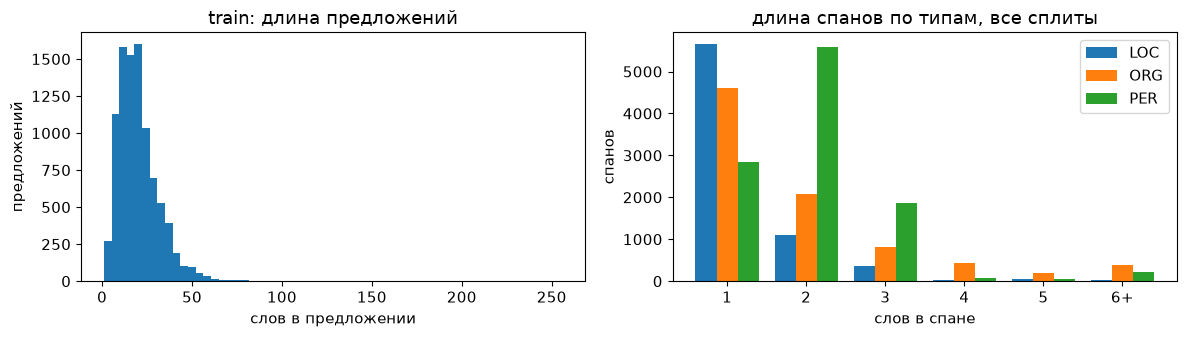

In [14]:
from seqeval.metrics.sequence_labeling import get_entities

types = sorted({tag[2:] for tag in LABEL_NAMES if tag != 'O'})
span_lengths = collections.defaultdict(list)
org_quotes = collections.Counter()
print(f'{"":<11}{"предложений":>12}{"слов":>8}{"доля O":>8}{"без сущностей":>15}' + ''.join(f'{t:>7}' for t in types))
for split, ds in raw.items():
    sentences = [get_entities([LABEL_NAMES[i] for i in tags]) for tags in ds['ner_tags']]
    counts = collections.Counter(kind for entities in sentences for kind, _, _ in entities)
    for words, entities in zip(ds['tokens'], sentences):
        for kind, start, end in entities:
            span_lengths[kind].append(end - start + 1)
            if kind == 'ORG':
                around = words[max(start - 1, 0):start] + words[end + 1:end + 2]
                org_quotes['в спане' if '"' in (words[start], words[end]) else
                           'сразу снаружи' if '"' in around else 'нет рядом'] += 1
    n_words = sum(len(words) for words in ds['tokens'])
    o_share = sum(LABEL_NAMES[i] == 'O' for tags in ds['ner_tags'] for i in tags) / n_words
    n_empty = sum(not entities for entities in sentences)
    print(f'{split:<11}{len(ds):>12}{n_words:>8}{o_share:>8.1%}{n_empty:>15}' + ''.join(f'{counts[t]:>7}' for t in types))

print('\nдлина спана в словах, все сплиты:')
for kind in types:
    lengths = collections.Counter(min(n, 4) for n in span_lengths[kind])
    shares = '  '.join(f'{label}: {lengths[n] / len(span_lengths[kind]):5.1%}'
                       for n, label in zip(range(1, 5), ['1', '2', '3', '4+']))
    print(f'{kind}  среднее {np.mean(span_lengths[kind]):.2f}, max {max(span_lengths[kind]):>2} | {shares}')
print('кавычка на краю ORG, все сплиты:', dict(org_quotes))

sent_lengths = {split: np.array([len(words) for words in ds['tokens']]) for split, ds in raw.items()}
print('\nдлина предложения в словах:')
for split, lengths in sent_lengths.items():
    print(f'{split:<11} среднее {lengths.mean():.1f}, медиана {np.median(lengths):.0f}, '
          f'95-й перцентиль {np.percentile(lengths, 95):.0f}, max {lengths.max()}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(sent_lengths['train'], bins=60)
axes[0].set(xlabel='слов в предложении', ylabel='предложений', title='train: длина предложений')
xs, width = np.arange(1, 7), 0.8 / len(types)
for k, kind in enumerate(types):
    lengths = collections.Counter(min(n, 6) for n in span_lengths[kind])
    axes[1].bar(xs - 0.4 + width * (k + 0.5), [lengths[x] for x in xs], width, label=kind)
axes[1].set_xticks(xs, ['1', '2', '3', '4', '5', '6+'])
axes[1].set(xlabel='слов в спане', ylabel='спанов', title='длина спанов по типам, все сплиты')
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 (`RCC-MSU/collection3`) состоит из русских новостей. Основа датасета — корпус Persons-1000: 1000 новостных документов, где изначально вручную размечены только персоны. Локации и организации доразметили вручную в Brat по правилам, близким к MUC-7. Перевод в IOB2 и разбиение на train / validation / test сделала команда DeepPavlov. В карточке указана лицензия `other`, раздел Licensing Information не заполнен; датасет есть в списке разрешенных в задании.

Типы сущностей PER, ORG и LOC. Предложений 9301 / 2153 / 1922. Сущностей по сплитам (PER / ORG / LOC):

| сплит | PER | ORG | LOC |
|---|---|---|---|
| train | 7406 | 5960 | 4881 |
| validation | 1641 | 1308 | 1168 |
| test | 1570 | 1256 | 1175 |

Доли типов по сплитам близкие: у LOC от 27% в train до 29% в test. Совсем редких типов нет, меньше всего LOC. Дисбаланс есть на уровне слов: 82–83% слов размечены тегом `O`, а 1815 предложений train (каждое пятое) вообще без сущностей.

По длине спанов типы различаются формой распределения:
- LOC почти всегда из одного слова (78%), в среднем 1.31 слова.
- PER в среднем 2.02 слова: чаще всего имя и фамилия (53%), длиннее трех слов — всего 3%.
- ORG в среднем 1.98 слова, но с самым длинным хвостом: 12% названий из 4 и больше слов, самое длинное — 18 слов, внутри встречаются кавычки и топонимы.

Предложения в среднем по 20 слов, 95% короче 42 слов, но в train есть хвост до 256 слов, и такие предложения обрежутся по `MAX_LENGTH`.

Шум разметки виден уже в статистике:
- Кавычки у названий размечены непоследовательно: у 380 ORG кавычка входит в спан, а у 1622 стоит сразу за границей.
- В 6 предложениях `I-X` стоит без `B-X` (см. 2.2).

Поэтому больше всего ошибок границ я жду на длинных ORG с кавычками.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, kind = [], None, None
    for i, tag in enumerate([*tags, 'O']):
        prefix, _, label = tag.partition('-')
        if start is not None and (prefix != 'I' or label != kind):
            spans.append((start, i, kind))
            start = None
        if start is None and prefix in ('B', 'I'):
            start, kind = i, label
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, kind in spans:
        if not 0 <= start < end <= n_words:
            raise ValueError(f'спан {(start, end, kind)} не помещается в {n_words} слов')
        tags[start:end] = [f'B-{kind}'] + [f'I-{kind}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, previous = [], None
    for word in word_ids:
        if word is None:
            labels.append(-100)
        elif word != previous:
            labels.append(word_labels[word])
        elif b_to_i is not None:
            labels.append(b_to_i.get(word_labels[word], word_labels[word]))
        else:
            labels.append(-100)
        previous = word
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

invalid_bio = []
for split, ds in raw.items():
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            f.write(json.dumps({'id': ex['id'], 'tokens': ex['tokens'], 'spans': spans}, ensure_ascii=False) + '\n')

    with path.open(encoding='utf-8') as f:
        records = [json.loads(line) for line in f]
    n_exact = 0
    for ex, rec in zip(ds, records, strict=True):
        tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
        restored = spans_to_bio([tuple(span) for span in rec['spans']], len(rec['tokens']))
        assert (rec['id'], rec['tokens']) == (ex['id'], ex['tokens'])
        assert bio_to_spans(restored) == bio_to_spans(tags) == [(s, e + 1, t) for t, s, e in get_entities(tags)]
        if restored == tags:
            n_exact += 1
        else:
            first = next(i for i, (a, b) in enumerate(zip(restored, tags)) if a != b)
            invalid_bio.append((split, ex['id'], list(zip(ex['tokens'], tags))[max(0, first - 3):first + 3]))
    print(f'{path}: {len(records)} предложений, {sum(len(r["spans"]) for r in records)} спанов, '
          f'BIO совпал дословно в {n_exact}')
print(path.read_text(encoding='utf-8').splitlines()[0][:220], '...')
print('\nI-X без B-X:')
for split, ex_id, context in invalid_bio:
    print(f'  {split} id={ex_id}: {context}')

print('\nсверка с токенизатором (без обрезки):')
for split, ds in raw.items():
    words_list = list(ds['tokens'])
    enc = tokenizer(words_list, is_split_into_words=True, add_special_tokens=False)
    too_long = sum(len(ids) + 2 > MAX_LENGTH for ids in enc['input_ids'])
    subwords_per_word = sum(map(len, enc['input_ids'])) / sum(map(len, words_list))
    print(f'{split:<11} длиннее {MAX_LENGTH} с [CLS] и [SEP]: {too_long}, сабвордов на слово {subwords_per_word:.2f}')
    for i, (words, tags) in enumerate(zip(words_list, ds['ner_tags'])):
        for w in sorted(set(range(len(words))) - set(enc.word_ids(i))):
            print(f'  слово без сабвордов {words[w]!r} с тегом {LABEL_NAMES[tags[w]]}: {" ".join(words[max(0, w - 2):w + 3])}')

data/train_spans.jsonl: 9301 предложений, 18247 спанов, BIO совпал дословно в 9296
data/validation_spans.jsonl: 2153 предложений, 4117 спанов, BIO совпал дословно в 2153
data/test_spans.jsonl: 1922 предложений, 4001 спанов, BIO совпал дословно в 1921
{"id": "0", "tokens": ["А", ".", "Силуанов", "назначен", "управляющим", "от", "России", "в", "МВФ"], "spans": [[0, 3, "PER"], [6, 7, "LOC"], [8, 9, "ORG"]]} ...

I-X без B-X:
  train id=1751: [('Воробьева', 'B-PER'), ('и', 'O'), ('.', 'O'), ('о', 'I-PER'), ('.', 'O'), ('главы', 'O')]
  train id=2524: [('Власть', 'I-ORG'), ('"', 'O'), ('Вероника', 'B-PER')]
  train id=3143: [('Ответственность', 'I-ORG'), ('.', 'I-ORG')]
  train id=3144: [('Процветание', 'I-ORG'), ('09', 'I-ORG'), ('"', 'I-ORG')]
  train id=7335: [('Северный', 'I-ORG'), ('Кавказ', 'I-ORG'), ('"', 'O')]
  test id=1242: [('Первоуральск', 'I-ORG'), ('"', 'O'), ('Ольгу', 'B-PER')]

сверка с токенизатором (без обрезки):


train       длиннее 128 с [CLS] и [SEP]: 8, сабвордов на слово 1.09
  слово без сабвордов '\xad' с тегом O: светский серд ­ цеед и
  слово без сабвордов '\xad' с тегом O: на внеш ­ неполитическом поприще
  слово без сабвордов '\xad' с тегом I-LOC: в Моск ­ ве ?
  слово без сабвордов '\xad' с тегом O: , ком ­ плектование материалов
validation  длиннее 128 с [CLS] и [SEP]: 0, сабвордов на слово 1.09


test        длиннее 128 с [CLS] и [SEP]: 0, сабвордов на слово 1.08
  слово без сабвордов '\xad' с тегом O: первым зам ­ предом правления


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']


train: проверено 9290 предложений, обрезано по MAX_LENGTH 8, слов без сабвордов или за обрезкой 386
[CLS]            None  -100
Допол               0  O
##нение             0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД                17  B-ORG
по                 18  O
субъектам          19  O
РФ                 20  B-LOC
.                  21  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Предсказывать и оценивать нужно слова, а тег слова берется с его первого сабворда (`predict_word_tags`). Поэтому и учим ровно эту позицию. Продолжения слова не добавляют в loss лишних голосов (иначе слово из трех сабвордов весило бы втрое больше слова из одного) и не учатся предсказывать `B-` в середине слова. -100 — это `ignore_index` у `CrossEntropyLoss`: такие позиции (спецтокены, паддинг, продолжения слов) не входят ни в сумму loss, ни в делитель при усреднении.

Обрезка и пропущенные слова:
- По `MAX_LENGTH` обрезано 8 предложений train, в validation и test ни одного. За обрезкой остается 382 слова: из 386 слов без меток в проверке выше 4 — мягкие переносы. Это касается только обучения, на метрику не влияет. На остальных 9290 предложениях проверка подтвердила, что метки первых сабвордов восстанавливают теги слов и спаны.
- Без сабвордов остались 5 слов, и все они — мягкий перенос `\xad`, который токенизатор выбрасывает: 4 в train и 1 в test. В test это `O`, на метрику не влияет. В train один перенос стоит внутри «Моск ­ ве» с тегом `I-LOC` и просто выпадает из обучения.

Проблемы конвертации. После экспорта в JSON и чтения обратно спаны совпали со спанами seqeval во всех предложениях. BIO не восстановился дословно только в 6 предложениях, где `I-X` стоит без `B-X` (5 в train, 1 в test). В пяти из них граница предложения разрезала название организации, и предложение начинается с хвоста названия: «Власть "», «Северный Кавказ "». Шестое — ошибка разметки: в «Воробьева и. о.» буква `о` помечена как `I-PER`. Пересекающихся и вложенных спанов в BIO не бывает. Токенизация датасета расходится с токенизатором модели только на мягких переносах, в среднем 1.09 сабворда на слово.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: tag_counts.most_common(1)[0][0] for word, tag_counts in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(majority, words) for words in val_tokens]

set_seed(SEED)
random_pred = predict_word_tags(make_model(), val_tokens)

baseline = {'majority': entity_scores(val_gold, majority_pred), 'random_head': entity_scores(val_gold, random_pred)}
for name, scores in baseline.items():
    print(f'{name:<12}', '  '.join(f'{metric} {value:.4f}' for metric, value in scores.items()))

train_entities = {(tuple(words[s:e]), kind) for words, tags in zip(train_tokens, train_tags) for s, e, kind in bio_to_spans(tags)}
val_entities = [(tuple(words[s:e]), kind) for words, tags in zip(val_tokens, val_gold) for s, e, kind in bio_to_spans(tags)]
print(f'\nсущностей validation, которые есть в train с тем же текстом и типом: {np.mean([e in train_entities for e in val_entities]):.1%}')
print('теги random_head:', collections.Counter(tag for tags in random_pred for tag in tags).most_common())
print('\nmajority по типам:')
print(classification_report(val_gold, majority_pred, digits=4, zero_division=0))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 55555.56it/s]

majority     f1_micro 0.5613  f1_macro 0.5786  precision 0.5626  recall 0.5601
random_head  f1_micro 0.0325  f1_macro 0.0318  precision 0.0189  recall 0.1166

сущностей validation, которые есть в train с тем же текстом и типом: 60.4%
теги random_head: [('I-LOC', 13931), ('O', 9441), ('B-LOC', 7470), ('I-PER', 4477), ('B-ORG', 4166), ('I-ORG', 2865), ('B-PER', 1506)]

majority по типам:
              precision    recall  f1-score   support

         LOC     0.7532    0.7628    0.7580      1168
         ORG     0.5492    0.5765    0.5625      1308
         PER     0.4284    0.4028    0.4152      1641

   micro avg     0.5626    0.5601    0.5613      4117
   macro avg     0.5769    0.5807    0.5786      4117
weighted avg     0.5589    0.5601    0.5592      4117



**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн дает на validation F1 по сущностям 0.561 (P 0.563, R 0.560, macro 0.579). Работает он только за счет повторов: 60.4% сущностей validation встречаются в train с тем же текстом и типом. Новости постоянно пишут про одни и те же страны, города, ведомства и политиков. Лучше всего выходит LOC (F1 0.758): спаны там в основном однословные и однозначные. Хуже всего PER (0.415), и причин две:
- Имена и фамилии каждый раз новые, а незнакомое слово получает `O`.
- Тег знакомого слова не зависит от контекста. Фамилия бывает и `B-PER` (стоит одна), и `I-PER` (после имени или инициала), а словарь всегда ставит самый частый вариант. Многословный PER получает неверную границу, и seqeval его не засчитывает.

ORG посередине (0.5625): частые аббревиатуры словарь знает, а длинные названия из нескольких слов собирает редко.

Энкодер со случайной головой дает F1 0.032 (P 0.019, R 0.117). Голова `Linear(768, 7)` инициализирована случайно, и argmax по ее логитам никак не связан с нашими тегами. Модель ставит `O` всего 9441 слову из 43 856 (21.5%), хотя в разметке их 83%, а чаще всего предсказывает `I-LOC` и `B-LOC`. Энкодер предобучен, и в его представлениях информация о сущностях есть, но без обученного отображения в наши 7 тегов ею никто не пользуется. Отсюда тысячи ложных спанов и почти нулевая precision, а редкие попадания в recall случайны.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 5e-5
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)
    attn_implementation = model.config._attn_implementation
    if device.type == 'mps':
        model.set_attn_implementation('eager')
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr, weight_decay=0.01, warmup_steps=0.1,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=2 * batch_size,
        eval_strategy='steps', eval_steps=0.05, logging_steps=0.05, save_strategy='no',
        fp16=device.type == 'cuda', dataloader_pin_memory=device.type == 'cuda',
        seed=SEED, report_to='none', disable_tqdm=False)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    model.set_attn_implementation(attn_implementation)
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 54075.78it/s]

Step,Training Loss,Validation Loss
44,1.073765,0.307725
88,0.127662,0.037508
132,0.049539,0.033031
176,0.037728,0.023301
220,0.034397,0.020259
264,0.032944,0.023004
308,0.030450,0.022787
352,0.015800,0.021074
396,0.021519,0.020518
440,0.024914,0.022035


обучение: 289.1 c на mps, 9301 предложений, 3 эпох(а)


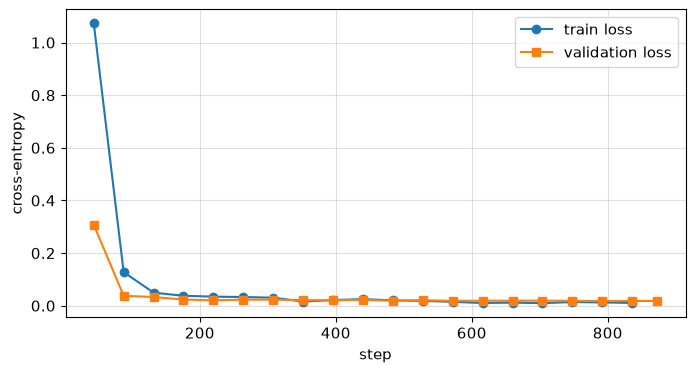

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Гиперпараметры типичные для дообучения BERT-base на NER:
- **lr 5e-5** для AdamW. Это верх обычного диапазона 2e-5 – 5e-5: шагов немного, 291 на эпоху и 873 за все обучение.
- **Прогрев** на первых 10% шагов, дальше линейное затухание до нуля. Прогрев нужен, чтобы случайная голова в начале не испортила энкодер большими градиентами.
- **weight decay 0.01** как слабая регуляризация.
- **batch 32**: предложения короткие, памяти с запасом.
- **3 эпохи**. Датасет небольшой (9301 предложение), а предобученному энкодеру на NER обычно хватает нескольких проходов. Больше эпох на маленьких данных скорее привели бы к переобучению, а кривые ниже показывают, хватило ли трех.

`fp16` включается только на CUDA, на MPS обучение идет в fp32.

По кривым переобучения нет:
- Train loss падает с 1.07 до 0.010.
- Validation loss уже к шагу 88 опускается до 0.038, к концу первой эпохи до 0.023, дальше держится на 0.018–0.022 и не растет.
- Разрыв train и validation в конце небольшой: 0.010 против 0.018.

Трех эпох хватило с запасом: всю третью эпоху validation loss почти не меняется (0.018–0.0195), так что можно было бы остановиться и раньше. Обучение заняло 289 с на Apple M5 Pro (MPS): 9301 предложение, 3 эпохи, 20 оценок на validation по ходу.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_gold = n_pred = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for g, p in zip(gold_tags, pred_tags, strict=True):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    return 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)

for split, gold, pred in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    scores = entity_scores(gold, pred)
    print(f'{split}: F1 micro {scores["f1_micro"]:.4f}, F1 macro {scores["f1_macro"]:.4f}, '
          f'токенный F1 {token_f1(gold, pred):.4f}')
    print(classification_report(gold, pred, digits=4, zero_division=0))

report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = {**entity_scores(test_gold, test_pred), 'token_f1': token_f1(test_gold, test_pred),
         'per_type': {kind: report[kind] for kind in ENTITY_TYPES},
         'validation': {**entity_scores(val_gold, val_pred), 'token_f1': token_f1(val_gold, val_pred)}}

validation: F1 micro 0.9815, F1 macro 0.9805, токенный F1 0.9846
              precision    recall  f1-score   support

         LOC     0.9856    0.9949    0.9902      1168
         ORG     0.9473    0.9618    0.9545      1308
         PER     0.9970    0.9970    0.9970      1641

   micro avg     0.9778    0.9852    0.9815      4117
   macro avg     0.9766    0.9845    0.9805      4117
weighted avg     0.9779    0.9852    0.9815      4117



test: F1 micro 0.9776, F1 macro 0.9762, токенный F1 0.9828
              precision    recall  f1-score   support

         LOC     0.9806    0.9915    0.9860      1175
         ORG     0.9380    0.9514    0.9447      1256
         PER     0.9987    0.9968    0.9978      1570

   micro avg     0.9742    0.9810    0.9776      4001
   macro avg     0.9725    0.9799    0.9762      4001
weighted avg     0.9743    0.9810    0.9777      4001



**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test F1 по сущностям 0.9776 (micro), 0.9762 (macro), токенный F1 0.9828. На validation 0.9815 / 0.9805 / 0.9846.

Хуже всего распознается ORG: F1 0.945 на test против 0.986 у LOC и 0.998 у PER. Дело не в частоте: организаций в данных даже больше, чем локаций. И не в средней длине: в среднем ORG почти такой же длины, как PER (1.98 и 2.02 слова). Отличие в разнообразии и хвосте:
- у ORG 12% названий из 4 и больше слов (у PER всего 3%), самое длинное — 18 слов;
- внутри названий бывают кавычки, топонимы и должности;
- кавычки в разметке то входят в спан, то нет (2.1).

Поэтому даже почти верный спан ORG легко теряет точное совпадение границ. PER почти идеален: имя с фамилией начинаются с заглавной буквы, а длина почти всегда 1–3 слова.

Micro F1 считается по всем спанам сразу, и в нем больше весит частый и легкий PER. Macro усредняет три типа поровну и поэтому чуть ниже (0.976 против 0.978). Разница маленькая: типов всего три, и по объему они сравнимы.

Токенный F1 выше сущностного (0.983 против 0.978), потому что засчитывает частичные совпадения. Если у ORG из трех слов модель потеряла одно слово, по словам это 2 верных из 3, а по сущностям ноль. Пользователю NER нужна сущность целиком, с правильными границами и типом, например чтобы вытащить название организации. Поэтому к его задаче ближе F1 по сущностям, а токенный F1 завышает качество как раз на ошибках границ, которые у нас главные (5.1).

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    gold_spans, pred_spans = [tuple(s) for s in gold_spans], [tuple(s) for s in pred_spans]

    def overlap(a, b):
        return min(a[1], b[1]) - max(a[0], b[0])

    result = []
    for gold in gold_spans:
        hits = [pred for pred in pred_spans if overlap(gold, pred) > 0]
        same_type = [pred for pred in hits if pred[2] == gold[2]]
        if gold in pred_spans:
            result.append(('correct', gold, gold))
        elif same_type:
            result.append(('boundary', gold, max(same_type, key=lambda pred: overlap(gold, pred))))
        elif hits:
            result.append(('type', gold, max(hits, key=lambda pred: overlap(gold, pred))))
        else:
            result.append(('missed', gold, None))
    result += [('spurious', None, pred) for pred in pred_spans
               if all(overlap(gold, pred) <= 0 for gold in gold_spans)]
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

cases = [(i, category, g, p)
         for i, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred))
         for category, g, p in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags))]
errors = {category: sum(c == category for _, c, _, _ in cases) for category in ERROR_CATEGORIES}
assert errors['correct'] == round(recall_score(val_gold, val_pred) * (len(cases) - errors['spurious']))

n_errors = len(cases) - errors['correct']
by_type = collections.Counter((c, (g or p)[2]) for _, c, g, p in cases)
print(f'{"":<10}{"всего":>7}{"доля ошибок":>13}' + ''.join(f'{t:>6}' for t in ENTITY_TYPES))
for category in ERROR_CATEGORIES:
    share = '' if category == 'correct' else f'{errors[category] / n_errors:.1%}'
    print(f'{category:<10}{errors[category]:>7}{share:>13}' + ''.join(f'{by_type[category, t]:>6}' for t in ENTITY_TYPES))
print('тип считается по истинному спану, у spurious - по предсказанному\n')

QUOTES = {'"', '«', '»'}


def without_edge_quotes(words, span):
    start, end = span[0], span[1]
    while start < end and words[start] in QUOTES:
        start += 1
    while end > start and words[end - 1] in QUOTES:
        end -= 1
    return start, end


boundary = [(val_tokens[i], g, p) for i, c, g, p in cases if c == 'boundary']
quote_only = sum(without_edge_quotes(words, g) == without_edge_quotes(words, p) for words, g, p in boundary)
spurious = [(tuple(val_tokens[i][p[0]:p[1]]), p[2]) for i, c, _, p in cases if c == 'spurious']
print(f'ошибок границ, где спаны отличаются только кавычками по краям: {quote_only} из {len(boundary)}')
print(f'лишних спанов, текст которых в train размечен как сущность того же типа: '
      f'{sum(entity in train_entities for entity in spurious)} из {len(spurious)}\n')


def span_text(words, span):
    return '-' if span is None else f'[{" ".join(words[span[0]:span[1]])}] {span[2]}'


rng = random.Random(SEED)
for category in ERROR_CATEGORIES[1:]:
    found = [case for case in cases if case[1] == category]
    for i, _, g, p in rng.sample(found, min(3, len(found))):
        words = val_tokens[i]
        print(f'{category:<9} gold {span_text(words, g):<34} pred {span_text(words, p):<34} | {" ".join(words)}')

            всего  доля ошибок   LOC   ORG   PER
correct      4056               1162  1258  1636
boundary       49        51.0%     1    45     3
type            4         4.2%     3     1     0
missed          8         8.3%     2     4     2
spurious       35        36.5%    13    20     2
тип считается по истинному спану, у spurious - по предсказанному

ошибок границ, где спаны отличаются только кавычками по краям: 29 из 49
лишних спанов, текст которых в train размечен как сущность того же типа: 12 из 35

boundary  gold [" Гражданской платформы "] ORG    pred [Гражданской платформы] ORG        | Лидера ярославского отделения " Гражданской платформы " могу арестовать на 15 суток
boundary  gold [Братья - мусульмане] ORG          pred [Братья - мусульмане "] ORG        | Он также заверил , что в случае , если Мубарак уйдет в отставку , " Братья - мусульмане " не будут стремиться к единоличной власти в стране .
boundary  gold [" ГП "] ORG                       pred [ГП] ORG            

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation точно найдены 4056 спанов, ошибок 96:
- **boundary** — 49 (51%), самая частая категория;
- **spurious** — 35 (36.5%);
- **missed** — 8;
- **type** — 4.

**boundary.** 45 ошибок границ из 49 приходятся на ORG, и главная их причина — кавычки. В 29 из 49 случаев предсказанный спан отличается от истинного только кавычками по краям. Если в разметке кавычки входят в спан, модель отдает «Гражданской платформы» и «ГП» без них. Бывает и наоборот: к «Братья - мусульмане» она прихватывает лишнюю кавычку.

**spurious.** В основном ORG и LOC, которых в этих предложениях нет в разметке: «Коммерсанта» в «По данным " Коммерсанта "», «РФ» в «заместителем Министра РФ по налогам и сборам», нарицательное «комитета».

**type.** Пограничные объекты вроде «Букингемского дворца» и «ЕЭС», которые можно отнести и к LOC, и к ORG. Сюда же попал случай, где модель выделила все «Министерства РФ по налогам и сборам ( МНС РФ )» как ORG, а в разметке внутри только «РФ» как LOC.

**missed.** Нарицательные или обрезанные спаны: «FM - радиостанцию», один «суд» вместо «Конституционный суд», «Центр» как название зоны лиги.

Заметная часть ошибок — на самом деле ошибки разметки:
- кавычки размечены непоследовательно (см. 2.1), отсюда 29 ошибок границ;
- у 12 из 35 лишних спанов тот же текст в train размечен как сущность того же типа, так что в этих предложениях разметчик ее, скорее всего, пропустил;
- «суд» размечен без «Конституционный»;
- «FM - радиостанцию» помечено как организация, хотя это нарицательное.

Чтобы уменьшить ошибки границ, я бы привел разметку к одному правилу для кавычек (например, всегда снаружи спана) и переобучил модель. На инференсе добавил бы постобработку, которая снимает крайние кавычки со спана. Это закрыло бы до 29 из 49 ошибок границ. Учить модель угадывать шум разметки бессмысленно.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'


def trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


ablation = {'setting': ABLATION, 'split': 'validation',
            'full': {**entity_scores(val_gold, val_pred), 'lr': LR, 'train_sec': RUN_TIMES['train_main_sec'],
                     'trainable_params': trainable_params(model)}}
for name, lr in [('freeze', LR), ('freeze_lr_1e-3', 1e-3)]:
    set_seed(SEED)
    frozen = make_model()
    _, seconds = train_ner(frozen, tokenized['train'], tokenized['validation'], lr=lr, freeze_encoder=True,
                           out_dir=f'runs/{name}')
    ablation[name] = {**entity_scores(val_gold, predict_word_tags(frozen, val_tokens)), 'lr': lr,
                      'train_sec': seconds, 'trainable_params': trainable_params(frozen)}

for name in ['full', 'freeze', 'freeze_lr_1e-3']:
    row = ablation[name]
    print(f'{name:<15} lr {row["lr"]:<7g} F1 {row["f1_micro"]:.4f}  P {row["precision"]:.4f}  R {row["recall"]:.4f}  '
          f'обучение {row["train_sec"]:5.0f} c  обучаемых параметров {row["trainable_params"]:,}')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 49080.96it/s]

Step,Training Loss,Validation Loss
44,1.902597,1.830250
88,1.724519,1.559904
132,1.436743,1.252829
176,1.166830,1.020081
220,0.984732,0.853715
264,0.849369,0.739471
308,0.740437,0.661741
352,0.676331,0.607916
396,0.632862,0.572357
440,0.592308,0.547857


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 47966.90it/s]

Step,Training Loss,Validation Loss
44,1.466113,0.710034
88,0.496965,0.307154
132,0.266359,0.193968
176,0.190543,0.156498
220,0.169186,0.134116
264,0.157342,0.120451
308,0.135249,0.110504
352,0.124168,0.104249
396,0.128652,0.099943
440,0.122096,0.095984


full            lr 5e-05   F1 0.9815  P 0.9778  R 0.9852  обучение   289 c  обучаемых параметров 177,722,119
freeze          lr 5e-05   F1 0.0344  P 0.2169  R 0.0187  обучение   143 c  обучаемых параметров 5,383
freeze_lr_1e-3  lr 0.001   F1 0.8545  P 0.8320  R 0.8783  обучение   144 c  обучаемых параметров 5,383


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** С замороженным энкодером и тем же lr 5e-5 модель почти ничего не выучила: F1 0.034 против 0.9815 у полного дообучения.
- Обучаемых параметров 5 383 вместо 177.7M.
- Обучение быстрее вдвое: 143 с против 289 с. Оба прогона на MPS шли с одной и той же eager-attention, так что время сравнимо. Прямой проход через 12 слоев все равно нужен, экономятся только backward и шаг оптимизатора по энкодеру.

Провал объясняется не признаками, а шагом обучения. lr 5e-5 подобран под дообучение всей сети, а одной линейной голове за 873 шага этого мало: validation loss к концу все еще 0.47.

Чтобы это проверить, я дополнительно обучил ту же замороженную модель с увеличенным lr 1e-3. Она дает F1 0.855 за то же время. Признаки предобученного энкодера уже неплохо разделяют сущности, но до дообученной модели далеко (0.855 против 0.9815): основной выигрыш дает подстройка самого энкодера под разметку.

Что бы я проверил дальше, чтобы вывод был надежнее:
- подобрать lr головы по сетке и дать ей больше эпох: с lr 1e-3 validation loss за последнюю эпоху еще снижается (0.086 → 0.082), хотя lr к концу затухает;
- повторить с несколькими seed;
- сравнить на test, а не только на validation.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообучение ruBert-base сработало: на validation F1 по сущностям 0.9815 против 0.561 у словарного бейзлайна и 0.032 у случайной головы, на test 0.978 (macro 0.976). Почти весь результат дает подстройка самого энкодера: линейная голова на замороженных признаках даже с увеличенным lr 1e-3 доходит только до 0.855. Стандартные гиперпараметры подошли без подбора: validation loss вышел на плато к концу первой эпохи, переобучения за 3 эпохи нет, обучение заняло меньше 5 минут на M5 Pro. Слабое место — ORG (0.945 на test): на ошибки границ ORG приходится 45 из 96 ошибок validation, и 29 ошибок границ отличаются от разметки только кавычками. Поэтому потолок здесь задает скорее разметка, чем модель: непоследовательные кавычки, пропущенные сущности (у 12 из 35 лишних спанов тот же текст в train размечен), обрезанные спаны вроде «суд» вместо «Конституционный суд». Ограничения эксперимента: один seed и одно разбиение, а validation и test из тех же новостей, так что на текстах без нормального регистра F1 падает до 0.34–0.67 (6.3). Кроме того, обучение на MPS недетерминировано, и повторный прогон того же ноутбука сдвигал test F1 в четвертом знаке (0.9776 и 0.9778). Дальше я бы унифицировал правило для кавычек, исправил явные ошибки разметки, добавил в обучение аугментацию регистра и повторил сравнения на нескольких seed.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "ai-forever/ruBert-base", "revision": "05f37a2ca9e333fd18f30cd0c96c68d274793c69", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 177722119, "ablation": {"setting": "freeze", "split": "validation", "full": {"f1_micro": 0.9814882032667877, "f1_macro": 0.980543270850585, "precision": 0.9778206364513018, "recall": 0.9851833859606509, "lr": 5e-05, "train_sec": 289.1279133749922, "trainable_params": 177722119}, "freeze": {"f1_micro": 0.034436493738819324, "f1_macro": 0.026688025443030932, "
final F1 micro 0.9776


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** 

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    SMALL_ID, SMALL_REVISION = 'cointegrated/rubert-tiny2', 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
    small_tok = AutoTokenizer.from_pretrained(SMALL_ID, revision=SMALL_REVISION)
    small_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                          fn_kwargs=dict(tok=small_tok))

    def describe(mdl, tok, train_sec):
        predict_word_tags(mdl, val_tokens[:128], tok=tok)
        start = time.perf_counter()
        val_p = predict_word_tags(mdl, val_tokens, tok=tok)
        infer_sec = time.perf_counter() - start
        test_p = predict_word_tags(mdl, test_tokens, tok=tok)
        return {'params': sum(p.numel() for p in mdl.parameters()),
                'weights_mb': sum(p.numel() * p.element_size() for p in mdl.parameters()) / 2**20,
                'train_sec': train_sec, 'val_infer_sec': infer_sec, 'val_f1': f1_score(val_gold, val_p),
                'test_f1': f1_score(test_gold, test_p), 'test_f1_macro': f1_score(test_gold, test_p, average='macro')}

    other_model = {f'{MODEL_ID}, lr {LR:g}': describe(model, tokenizer, RUN_TIMES['train_main_sec'])}
    for lr in (LR, 2e-4):
        set_seed(SEED)
        small = make_model(SMALL_ID, SMALL_REVISION)
        _, seconds = train_ner(small, small_data['train'], small_data['validation'], lr=lr, tok=small_tok,
                               out_dir='runs/small')
        other_model[f'{SMALL_ID}, lr {lr:g}'] = describe(small, small_tok, seconds)

    print(f'{"":<36}{"параметров":>12}{"MB":>6}{"обучение, c":>13}{"инференс val, c":>17}'
          f'{"F1 val":>8}{"F1 test":>9}{"macro test":>12}')
    for name, row in other_model.items():
        print(f'{name:<36}{row["params"]:>12,}{row["weights_mb"]:>6.0f}{row["train_sec"]:>13.0f}'
              f'{row["val_infer_sec"]:>17.1f}{row["val_f1"]:>8.4f}{row["test_f1"]:>9.4f}{row["test_f1_macro"]:>12.4f}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 40953.96it/s]

Step,Training Loss,Validation Loss
44,1.518689,0.886782
88,0.596872,0.342243
132,0.303478,0.201386
176,0.196408,0.137387
220,0.156575,0.102520
264,0.131234,0.095625
308,0.105968,0.078179
352,0.086338,0.074884
396,0.094774,0.069867
440,0.081185,0.064788


Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 38406.72it/s]

Step,Training Loss,Validation Loss
44,1.107739,0.400081
88,0.269942,0.128522
132,0.132451,0.078042
176,0.096898,0.068476
220,0.083003,0.053400
264,0.074831,0.057849
308,0.060224,0.044953
352,0.036382,0.045043
396,0.045461,0.045798
440,0.040343,0.043111


                                      параметров    MB  обучение, c  инференс val, c  F1 val  F1 test  macro test
ai-forever/ruBert-base, lr 5e-05     177,722,119   678          289              4.1  0.9815   0.9776      0.9762
cointegrated/rubert-tiny2, lr 5e-05   29,098,303   111           34              0.5  0.8959   0.9004      0.8973
cointegrated/rubert-tiny2, lr 0.0002  29,098,303   111           33              0.5  0.9299   0.9282      0.9256


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** По качеству лучше ruBert-base: F1 на test 0.978 против 0.928 у rubert-tiny2 с lr 2e-4 и 0.900 у нее же с lr 5e-5.

Цена — размер и время:

| | ruBert-base | rubert-tiny2 | во сколько раз |
|---|---|---|---|
| параметров | 177.7M | 29.1M | 6 |
| веса в fp32 | 678 MB | 111 MB | 6 |
| обучение | 289 с | 33 с | 9 |
| разметка всего validation на MPS | 4.1 с | 0.5 с | 8 |

Память при обучении я не мерил. Оценка по весам, градиентам и двум моментам AdamW (16 байт на параметр, без активаций): около 2.8 ГБ против 0.47 ГБ.

Как я обеспечил честность сравнения. Одинаковые:
- подмножества train / validation / test;
- `train_ner` (эпохи, batch, warmup, weight decay, seed);
- предсказание по первому сабворду через `predict_word_tags` и seqeval;
- устройство.

Различаются:
- токенизатор: у каждой модели свой, а метки на сабворды переносит та же `align_labels`;
- lr. С общим lr 5e-5 маленькая модель недоучивается: к концу train loss 0.058 против 0.019 при lr 2e-4, validation loss 0.055 против 0.041. Поэтому я показал оба варианта. Даже с подобранным lr разрыв около 5 пунктов F1.

Если важна скорость или нет GPU, tiny с F1 0.93 — разумный выбор. Для качества лучше base.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                        ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's',
                         't', 'u', 'f', 'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))

    def translit(word):
        latin = ''.join(TRANSLIT.get(ch.lower(), ch).capitalize() if ch.isupper() else TRANSLIT.get(ch, ch)
                        for ch in word)
        return latin or word

    def add_typo(word, rng, p=0.3):
        if len(word) < 4 or not word.isalpha() or rng.random() >= p:
            return word
        i = rng.randrange(1, len(word) - 1)
        edit = rng.choice(['swap', 'drop', 'double'])
        if edit == 'swap':
            return word[:i] + word[i + 1] + word[i] + word[i + 2:]
        if edit == 'drop':
            return word[:i] + word[i + 1:]
        return word[:i] + word[i] + word[i:]

    typo_rng = random.Random(SEED)
    corruptions = {'clean': lambda w: w, 'lower': str.lower, 'upper': str.upper,
                   'typos 30%': lambda w: add_typo(w, typo_rng), 'translit': translit}
    shift = {}
    for name, corrupt in corruptions.items():
        tokens = [[corrupt(w) for w in words] for words in val_tokens]
        pred = predict_word_tags(model, tokens)
        report = classification_report(val_gold, pred, output_dict=True, zero_division=0)
        subwords = tokenizer(tokens, is_split_into_words=True, add_special_tokens=False)['input_ids']
        shift[name] = {'f1_micro': f1_score(val_gold, pred),
                       **{kind: report[kind]['f1-score'] for kind in ENTITY_TYPES},
                       'subwords_per_word': sum(map(len, subwords)) / sum(map(len, tokens)),
                       'example': ' '.join(tokens[1][:10])}

    print(f'{"":<11}{"F1":>8}{"разница":>9}' + ''.join(f'{t:>8}' for t in ENTITY_TYPES) + f'{"сабв./слово":>13}  пример')
    for name, row in shift.items():
        print(f'{name:<11}{row["f1_micro"]:>8.4f}{row["f1_micro"] - shift["clean"]["f1_micro"]:>+9.4f}'
              + ''.join(f'{row[t]:>8.4f}' for t in ENTITY_TYPES) + f'{row["subwords_per_word"]:>13.2f}  {row["example"]}')

                 F1  разница     LOC     ORG     PER  сабв./слово  пример
clean        0.9815  +0.0000  0.9902  0.9545  0.9970         1.09  Президент США Барак Обама в пятницу , 19 июня ,
lower        0.3381  -0.6434  0.3352  0.2228  0.4085         1.17  президент сша барак обама в пятницу , 19 июня ,
upper        0.6710  -0.3105  0.6549  0.5512  0.7672         2.72  ПРЕЗИДЕНТ США БАРАК ОБАМА В ПЯТНИЦУ , 19 ИЮНЯ ,
typos 30%    0.9507  -0.0308  0.9589  0.9190  0.9699         1.38  Президент США Барак Обама в пятницу , 19 иня ,
translit     0.5463  -0.4352  0.3358  0.4810  0.6746         2.81  Prezident SShA Barak Obama v pyatnitsu , 19 iyunya ,


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего бьет нижний регистр: F1 падает с 0.9815 до 0.338. При этом слово режется почти так же: 1.17 сабворда против 1.09. Значит, главный признак сущности для модели — заглавная буква. Без нее «барак обама», «сша» и «россии» выглядят как обычные слова. Особенно страдает ORG (0.223): он часто держится на заглавных аббревиатурах и названиях.

Верхний регистр (0.671) и транслит (0.546) ломают уже токенизацию: слово режется в среднем на 2.7–2.8 сабворда, и модель видит незнакомые куски капса или латиницы. Капс к тому же стирает разницу между обычным словом и аббревиатурой: все слова выглядят как «МВД». Лучше всех в обоих случаях держится PER (0.77 и 0.67). Имя с фамилией идут парой подряд и часто стоят после слов вроде «президент», так что их выдает контекст, а не написание.

Опечатки в 30% длинных слов почти не мешают: 0.9507, то есть −0.031. Первая буква с регистром остается, а соседние слова дают контекст.

Если модель будет работать с текстами без нормального регистра (соцсети, поисковые запросы, распознанная речь), первым делом стоит добавить в обучение аугментацию регистра: случайно переводить часть предложений в нижний и верхний регистр.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    %pip install -q onnx onnxruntime onnxscript
    import onnxruntime as ort
    from onnxruntime.quantization import QuantType, quantize_dynamic
    from onnxruntime.quantization.shape_inference import quant_pre_process
    from transformers.modeling_outputs import TokenClassifierOutput

    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).to(cpu).eval()
    onnx_dir = Path('runs/onnx')
    onnx_dir.mkdir(parents=True, exist_ok=True)
    fp32_path, prep_path, int8_path = (onnx_dir / name for name in ('ner.onnx', 'ner.prep.onnx', 'ner.int8.onnx'))

    example = dict(tokenizer(val_tokens[:2], is_split_into_words=True, padding=True, return_tensors='pt'))
    dynamic = {name: {0: torch.export.Dim.DYNAMIC, 1: torch.export.Dim.DYNAMIC} for name in example}
    torch.onnx.export(cpu_model, (), str(fp32_path), kwargs=example, input_names=list(example), output_names=['logits'],
                      dynamic_shapes=dynamic, external_data=False, dynamo=True, verbose=False)
    quant_pre_process(str(fp32_path), str(prep_path), skip_symbolic_shape=True)
    quantize_dynamic(prep_path, int8_path, weight_type=QuantType.QInt8)

    class OnnxTagger:
        def __init__(self, path):
            options = ort.SessionOptions()
            options.intra_op_num_threads = torch.get_num_threads()
            self.session = ort.InferenceSession(str(path), options, providers=['CPUExecutionProvider'])
            self.input_names = [i.name for i in self.session.get_inputs()]
            self.config = model.config

        def eval(self):
            return self

        def to(self, device):
            return self

        def __call__(self, **enc):
            logits = self.session.run(['logits'], {name: enc[name].numpy() for name in self.input_names})[0]
            return TokenClassifierOutput(logits=torch.from_numpy(logits))

    def weights_mb(mdl):
        return sum(p.numel() * p.element_size() for p in mdl.parameters()) / 2**20

    def latency_ms(run, runs=20):
        with torch.inference_mode():
            for _ in range(3):
                run()
            start = time.perf_counter()
            for _ in range(runs):
                run()
        return (time.perf_counter() - start) / runs * 1000

    variants = [('PyTorch fp32', cpu_model, cpu, weights_mb(cpu_model)),
                ('ONNX Runtime fp32', OnnxTagger(fp32_path), cpu, fp32_path.stat().st_size / 2**20),
                ('ONNX Runtime int8', OnnxTagger(int8_path), cpu, int8_path.stat().st_size / 2**20)]
    if device.type != 'cpu':
        half_model = copy.deepcopy(model).to(device).half()
        variants += [('PyTorch fp32', model, device, weights_mb(model)),
                     ('PyTorch fp16', half_model, device, weights_mb(half_model))]

    bench = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                      padding=True, return_tensors='pt')
    export_speed = {}
    for name, tagger, dev, size_mb in variants:
        inputs = {k: v.to(dev) for k, v in bench.items()}
        pred = predict_word_tags(tagger, val_tokens, dev=dev)
        export_speed[f'{dev.type} {name}'] = {
            'device': dev.type, 'size_mb': size_mb, 'f1_micro': f1_score(val_gold, pred),
            'token_f1': token_f1(val_gold, pred), 'latency_ms': latency_ms(lambda: tagger(**inputs).logits.cpu())}

    blas = re.search(r'BLAS_INFO=(\w+)', torch.__config__.show())
    print(f'батч {tuple(bench["input_ids"].shape)}, среднее по 20 запускам после 3 прогревочных, '
          f'на CPU у PyTorch и ONNX Runtime по {torch.get_num_threads()} потоков, BLAS у PyTorch: {blas and blas.group(1)}')
    for name, row in export_speed.items():
        base = export_speed[f'{row["device"]} PyTorch fp32']['latency_ms']
        print(f'{name:<22} {row["latency_ms"]:7.1f} мс  x{base / row["latency_ms"]:.2f}  {row["size_mb"]:4.0f} MB  '
              f'F1 val {row["f1_micro"]:.4f}  токенный F1 {row["token_f1"]:.4f}')

Note: you may need to restart the kernel to use updated packages.


батч (32, 43), среднее по 20 запускам после 3 прогревочных, на CPU у PyTorch и ONNX Runtime по 6 потоков, BLAS у PyTorch: accelerate
cpu PyTorch fp32         180.6 мс  x1.00   678 MB  F1 val 0.9815  токенный F1 0.9846
cpu ONNX Runtime fp32    152.8 мс  x1.18   679 MB  F1 val 0.9815  токенный F1 0.9846
cpu ONNX Runtime int8    142.3 мс  x1.27   170 MB  F1 val 0.9800  токенный F1 0.9841
mps PyTorch fp32          41.0 мс  x1.00   678 MB  F1 val 0.9815  токенный F1 0.9846
mps PyTorch fp16          12.7 мс  x3.23   339 MB  F1 val 0.9814  токенный F1 0.9845


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Замер на одном батче 32 × 43 на CPU M5 Pro, 6 потоков и у PyTorch, и у ONNX Runtime, среднее по 20 запускам после прогрева:
- **ONNX Runtime fp32:** x1.18 (181 мс → 153 мс), метрика не изменилась совсем.
- **Динамическая int8-квантизация в ONNX Runtime:** x1.27 (142 мс), файл в 4 раза меньше (170 MB против 678 MB). F1 на validation падает на 0.0015, с 0.9815 до 0.9800.
- **fp16 на GPU (для сравнения):** самый большой выигрыш дает не экспорт, а half precision. На MPS тот же батч считается за 12.7 мс вместо 41.0 мс (x3.23), F1 меняется на 0.0001.

Почему выигрыш на CPU скромный. Больше половины параметров модели (52%) — таблица эмбеддингов. Она занимает память, но на вычисления почти не влияет: это просто выборка строк. Поэтому int8 сильно уменьшает файл, а ускоряет только матричные умножения в 12 слоях энкодера. К тому же PyTorch здесь собран с Apple Accelerate (в выводе `BLAS у PyTorch: accelerate`), так что fp32-умножения на CPU у него и так быстрые, и запаса для ускорения мало.

Почему выигрыш зависит от модели. Если основное время уходит в слои энкодера (длинные последовательности, больше слоев), квантизация и fp16 дают больше. У маленькой rubert-tiny2 время слоев небольшое, заметную долю съедают токенизация и накладные расходы, и выигрыш от ускорения матричных умножений, скорее всего, был бы еще меньше.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

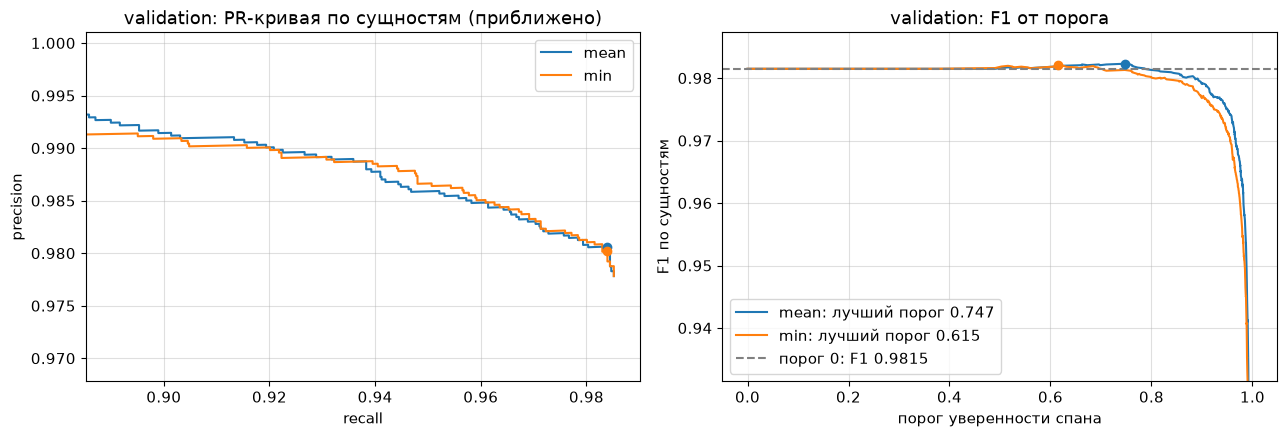

предсказанных спанов validation 4148, из них верных 4056, однословных 51.9%
mean  порог 0.7473: validation F1 0.9815 -> 0.9823 (P 0.9806, R 0.9840), отброшено 17 спанов, из них верных 5; test F1 0.9776 -> 0.9784
min   порог 0.6145: validation F1 0.9815 -> 0.9821 (P 0.9802, R 0.9840), отброшено 15 спанов, из них верных 5; test F1 0.9776 -> 0.9789


In [34]:
if '6.5' in BONUS_TASKS:
    def span_confidences(tokens_list, gold_tags):
        pred_tags, probs = predict_word_tags(model, tokens_list, return_probs=True)
        rows = []
        for gold, pred, conf in zip(gold_tags, pred_tags, probs):
            gold_spans = set(bio_to_spans(gold))
            for start, end, kind in bio_to_spans(pred):
                rows.append((np.mean(conf[start:end]), np.min(conf[start:end]), (start, end, kind) in gold_spans))
        mean_conf, min_conf, correct = map(np.array, zip(*rows))
        n_gold = sum(len(bio_to_spans(tags)) for tags in gold_tags)
        return {'mean': mean_conf, 'min': min_conf}, correct, n_gold

    def pr_curve(conf, correct, n_gold, thresholds):
        kept = conf[None, :] >= thresholds[:, None]
        n_kept, tp = kept.sum(1), (kept & correct).sum(1)
        precision = np.where(n_kept > 0, tp / np.maximum(n_kept, 1), 1.0)
        return precision, tp / n_gold, 2 * tp / (n_kept + n_gold)

    val_conf, val_correct, val_n_gold = span_confidences(val_tokens, val_gold)
    test_conf, test_correct, test_n_gold = span_confidences(test_tokens, test_gold)

    span_threshold = {}
    fig, (ax_pr, ax_f1) = plt.subplots(1, 2, figsize=(13, 4.5))
    for kind in ['mean', 'min']:
        thresholds = np.unique(np.concatenate([[0.0], val_conf[kind]]))
        precision, recall, f1 = pr_curve(val_conf[kind], val_correct, val_n_gold, thresholds)
        best = int(np.argmax(f1))
        dropped = val_conf[kind] < thresholds[best]
        test_f1 = pr_curve(test_conf[kind], test_correct, test_n_gold, thresholds[[0, best]])[2]
        span_threshold[kind] = {'threshold': thresholds[best], 'val_f1_at_0': f1[0], 'val_f1_best': f1[best],
                                'val_precision': precision[best], 'val_recall': recall[best],
                                'dropped_spans': int(dropped.sum()), 'dropped_correct': int((dropped & val_correct).sum()),
                                'test_f1_at_0': test_f1[0], 'test_f1_at_threshold': test_f1[1]}
        line, = ax_pr.plot(recall, precision, label=f'{kind}')
        ax_pr.scatter([recall[best]], [precision[best]], color=line.get_color(), zorder=3)
        ax_f1.plot(thresholds, f1, color=line.get_color(), label=f'{kind}: лучший порог {thresholds[best]:.3f}')
        ax_f1.scatter([thresholds[best]], [f1[best]], color=line.get_color(), zorder=3)
    r0, p0, f0 = recall[0], precision[0], f1[0]
    top = max(row['val_f1_best'] for row in span_threshold.values())
    ax_pr.set(xlim=(r0 - 0.1, r0 + 0.005), ylim=(p0 - 0.01, 1.001), xlabel='recall', ylabel='precision',
              title='validation: PR-кривая по сущностям (приближено)')
    ax_f1.axhline(f0, color='gray', linestyle='--', label=f'порог 0: F1 {f0:.4f}')
    ax_f1.set(ylim=(f0 - 0.05, top + 0.005), xlabel='порог уверенности спана', ylabel='F1 по сущностям',
              title='validation: F1 от порога')
    for ax in (ax_pr, ax_f1):
        ax.legend()
        ax.grid(alpha=0.4)
    plt.tight_layout()
    plt.show()

    assert abs(span_threshold['mean']['val_f1_at_0'] - final['validation']['f1_micro']) < 1e-9
    print(f'предсказанных спанов validation {len(val_correct)}, из них верных {val_correct.sum()}, '
          f'однословных {np.mean(val_conf["mean"] == val_conf["min"]):.1%}')
    for kind, row in span_threshold.items():
        print(f'{kind:<5} порог {row["threshold"]:.4f}: validation F1 {row["val_f1_at_0"]:.4f} -> {row["val_f1_best"]:.4f} '
              f'(P {row["val_precision"]:.4f}, R {row["val_recall"]:.4f}), отброшено {row["dropped_spans"]} спанов, '
              f'из них верных {row["dropped_correct"]}; test F1 {row["test_f1_at_0"]:.4f} -> {row["test_f1_at_threshold"]:.4f}')

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Лучший порог на validation — 0.747 для средней уверенности и 0.615 для минимальной. Прибавляют они совсем немного:

| уверенность | порог | F1 validation | отброшено спанов (из них верных) | F1 test с тем же порогом |
|---|---|---|---|---|
| средняя | 0.747 | 0.9815 → 0.9823 | 17 (5) | 0.9776 → 0.9784 |
| минимальная | 0.615 | 0.9815 → 0.9821 | 15 (5) | 0.9776 → 0.9789 |

Модель почти всегда уверена в своих спанах. На графике F1 стоит ровно примерно до порога 0.75–0.8 и дальше быстро падает, а лучший порог отбрасывает лишь 15–17 спанов из 4148. Прибавка порядка тысячной — на уровне шума.

Средняя и минимальная уверенность совпадают на однословных спанах, а их 51.9%. На длинных спанах минимальная строже: одно неуверенное слово в длинном ORG отбраковывает весь спан, тогда как средняя его прощает. Минимум никогда не больше среднего, поэтому для минимальной лучший порог ниже.

Порог по уверенности не может поднять recall: он только убирает спаны из уже предсказанных и не добавляет новых, поэтому recall при росте порога может лишь падать или стоять на месте. Чтобы поднять recall, нужно, наоборот, чаще выбирать тег сущности против `O` на уровне слов, например понижать вероятность `O` перед argmax, а не фильтровать готовые спаны.